In [ ]:
%pip install -U "transformers>=5.17.0" accelerate pillow safetensors bitsandbytes
%pip install -U git+https://github.com/huggingface/diffusers
%pip install -U --no-deps "torchao>=0.15.0"
# 安装完成后：Runtime（运行时）→ Restart session（重启会话）

In [1]:
import torch, sys
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
GPU: Tesla T4
VRAM GiB: 14.56


In [2]:
import torch, time
from diffusers import QwenImage21Pipeline
from diffusers.quantizers import PipelineQuantizationConfig

model_id = "Qwen/Qwen-Image-2.1"
quant_config = PipelineQuantizationConfig(
    quant_backend="bitsandbytes_4bit",
    quant_kwargs={
        "load_in_4bit": True,
        "bnb_4bit_quant_type": "nf4",
        "bnb_4bit_compute_dtype": torch.float16,
    },
    components_to_quantize=["transformer", "text_encoder"],
)

start = time.time()
pipe = QwenImage21Pipeline.from_pretrained(
    model_id,
    dtype=torch.float16,
    low_cpu_mem_usage=True,
    device_map="cuda",
    quantization_config=quant_config,
)
print(f"载入耗时：{(time.time()-start)/60:.1f} 分钟")
print("GPU 已分配 GiB：", round(torch.cuda.memory_allocated()/1024**3, 2))

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 23 files:   0%|          | 0/23 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

载入耗时：9.1 分钟
GPU 已分配 GiB： 10.66


  0%|          | 0/20 [00:00<?, ?it/s]

尺寸： (512, 512) 耗时： 22.7 秒


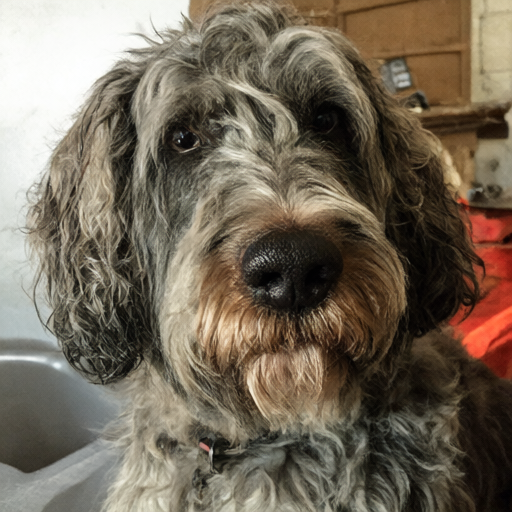

In [6]:
from IPython.display import display
import time

prompt = "A DOG"
start = time.time()
with torch.inference_mode():
    image = pipe(
        prompt,
        width=512,
        height=512,
        num_inference_steps=20,
        generator=torch.Generator("cuda").manual_seed(42),
    ).images[0]
image.save("/content/qwen21_t4_nf4_20steps.png")
print("尺寸：", image.size, "耗时：", round(time.time()-start, 1), "秒")
display(image)